# 01 - Phân tích dữ liệu khám phá (EDA)

Mục tiêu: xem dữ liệu có gì, ý nghĩa từng cột, thống kê, giá trị thiếu và số lượng giá trị của mỗi cột.

In [59]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math 
df = pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Dữ liệu có gì?

Xem số dòng, số cột và kiểu dữ liệu.

In [60]:
df[df['TotalCharges'].str.strip() == ''] # → 11 dòng

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [61]:
print('Số dòng:', df.shape[0])
print('Số cột:', df.shape[1])
df.info()

Số dòng: 7043
Số cột: 21
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-n

## 2. Ý nghĩa từng cột

| Cột | Ý nghĩa |
|---|---|
| customerID | Mã khách hàng |
| gender | Giới tính |
| SeniorCitizen | Người cao tuổi (0 = Không, 1 = Có) |
| Partner | Có vợ/chồng |
| Dependents | Có người phụ thuộc |
| tenure | Số tháng khách hàng ở lại |
| PhoneService | Có dùng điện thoại |
| MultipleLines | Nhiều đường điện thoại |
| InternetService | Loại internet (DSL, Fiber optic, No) |
| OnlineSecurity | Bảo mật trực tuyến |
| OnlineBackup | Sao lưu trực tuyến |
| DeviceProtection | Bảo vệ thiết bị |
| TechSupport | Hỗ trợ kỹ thuật |
| StreamingTV | Truyền hình trực tuyến |
| StreamingMovies | Phim trực tuyến |
| Contract | Loại hợp đồng |
| PaperlessBilling | Hóa đơn điện tử |
| PaymentMethod | Cách thanh toán |
| MonthlyCharges | Phí mỗi tháng |
| TotalCharges | Tổng phí đã trả |
| **Churn** | **Khách rời đi hay không (target)** |




In [62]:
# Cắt bỏ dòng đầu tiên (hoặc hàng tiêu đề/ID nếu cần)
df_noID = df.drop(columns=['customerID'])
df_noID = df_noID.select_dtypes("object")
for col in df_noID.columns:  # Sửa lại bỏ dấu () ở columns
  print('---', col, '---')
  print(df_noID[col].unique())  # Dùng df_noID để lấy đúng dữ liệu đã cắt
  print()

--- gender ---
<StringArray>
['Female', 'Male']
Length: 2, dtype: str

--- Partner ---
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

--- Dependents ---
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

--- PhoneService ---
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

--- MultipleLines ---
<StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str

--- InternetService ---
<StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

--- OnlineSecurity ---
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

--- OnlineBackup ---
<StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str

--- DeviceProtection ---
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

--- TechSupport ---
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

--- StreamingTV ---
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

--- StreamingMovies ---
<StringArray>
['No', 'Yes', 'No in

/tmp/ipykernel_493179/3518775691.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_noID = df_noID.select_dtypes("object")


# Ý nghĩa các trường dữ liệu (Dataset: Telco Customer Churn)

---

### 1. Nhóm thông tin nhân khẩu học (Demographics)
* **`gender`** *(Giới tính)*:
  * `Female`: Khách hàng nữ.
  * `Male`: Khách hàng nam.
* **`Partner`** *(Tình trạng kết hôn / Có người sống chung)*:
  * `Yes`: Có vợ/chồng hoặc người sống chung.
  * `No`: Sống độc thân.
* **`Dependents`** *(Người phụ thuộc)*:
  * `Yes`: Có người phụ thuộc (con cái, người già,...).
  * `No`: Không có người phụ thuộc.

---

### 2. Nhóm dịch vụ Viễn thông & Internet cơ bản
* **`PhoneService`** *(Dịch vụ điện thoại)*:
  * `Yes`: Có đăng ký dịch vụ điện thoại cố định.
  * `No`: Không đăng ký.
* **`MultipleLines`** *(Nhiều đường dây điện thoại)*:
  * `Yes`: Sử dụng nhiều đường dây điện thoại.
  * `No`: Chỉ dùng 1 đường dây.
  * `No phone service`: Không đăng ký dịch vụ điện thoại.
* **`InternetService`** *(Loại hình Internet)*:
  * `DSL`: Cáp đồng kỹ thuật số (Digital Subscriber Line).
  * `Fiber optic`: Cáp quang tốc độ cao.
  * `No`: Không sử dụng dịch vụ Internet.

---

### 3. Nhóm dịch vụ giá trị gia tăng (Add-on Services)
*(Tất cả các dịch vụ dưới đây sẽ có giá trị `No internet service` nếu khách hàng không đăng ký Internet)*
* **`OnlineSecurity`** *(Bảo mật trực tuyến)*: `Yes` | `No` | `No internet service`
* **`OnlineBackup`** *(Sao lưu dữ liệu trực tuyến)*: `Yes` | `No` | `No internet service`
* **`DeviceProtection`** *(Bảo hiểm / Bảo vệ thiết bị)*: `Yes` | `No` | `No internet service`
* **`TechSupport`** *(Dịch vụ hỗ trợ kỹ thuật chuyên sâu)*: `Yes` | `No` | `No internet service`
* **`StreamingTV`** *(Truyền hình trực tuyến)*: `Yes` | `No` | `No internet service`
* **`StreamingMovies`** *(Xem phim trực tuyến)*: `Yes` | `No` | `No internet service`

---

### 4. Nhóm Hợp đồng & Thanh toán (Contract & Billing)
* **`Contract`** *(Hình thức hợp đồng)*:
  * `Month-to-month`: Hợp đồng theo tháng (linh hoạt, dễ hủy).
  * `One year`: Hợp đồng cam kết 1 năm.
  * `Two year`: Hợp đồng cam kết 2 năm.
* **`PaperlessBilling`** *(Hóa đơn điện tử)*:
  * `Yes`: Nhận hóa đơn điện tử qua email/ứng dụng.
  * `No`: Nhận hóa đơn giấy truyền thống.
* **`PaymentMethod`** *(Phương thức thanh toán)*:
  * `Electronic check`: Thanh toán qua séc điện tử.
  * `Mailed check`: Thanh toán bằng séc qua đường bưu điện.
  * `Bank transfer (automatic)`: Chuyển khoản ngân hàng tự động.
  * `Credit card (automatic)`: Thanh toán tự động qua thẻ tín dụng.
* **`TotalCharges`** *(Tổng chi phí)*:
  * Kiểu dữ liệu chuỗi chứa số (ví dụ: `'29.85'`, `'1889.5'`) thể hiện tổng số tiền khách hàng đã thanh toán tích lũy. *(Lưu ý ép kiểu sang `float` trước khi đưa vào mô hình).*

---

### 5. Biến mục tiêu (Target Variable)
* **`Churn`** *(Trạng thái rời bỏ dịch vụ)*:
  * `Yes`: Khách hàng đã chấm dứt hợp đồng / rời bỏ nhà mạng.
  * `No`: Khách hàng vẫn đang tiếp tục sử dụng dịch vụ.

## ý nghĩa giá trị bên trong mỗi cột


> `No phone service` = không dùng điện thoại, `No internet service` = không dùng internet. Đây **không phải** dữ liệu thiếu.

## 3. Thống kê mô tả

Giá trị nhỏ nhất, lớn nhất, trung bình của các cột số.

In [63]:
num_cols = df.select_dtypes(include=["number"]).columns
object_cols = df.select_dtypes(include=["object"]).columns

/tmp/ipykernel_493179/1347891021.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_cols = df.select_dtypes(include=["object"]).columns


In [64]:
print(len(num_cols))
print(len(object_cols))

3
18


In [65]:
df[num_cols].describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [66]:
df[object_cols].describe()

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


## 4. Missing value

Đếm số ô trống trong từng cột.

In [67]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

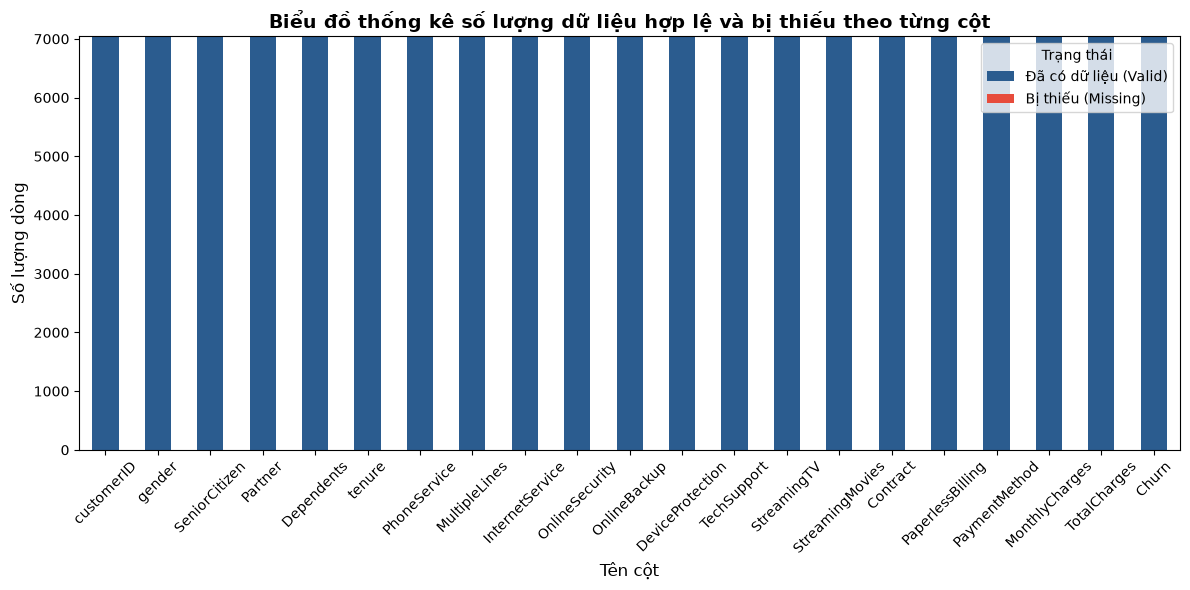

In [68]:
# 1. Tính số lượng dữ liệu thiếu và không thiếu của từng cột
missing_count = df.isnull().sum()
valid_count = df.notnull().sum()

# Ghép lại thành một DataFrame tạm để vẽ biểu đồ
summary_df = pd.DataFrame({
    'Đã có dữ liệu (Valid)': valid_count,
    'Bị thiếu (Missing)': missing_count
})

# 2. Vẽ biểu đồ cột chồng (Stacked Bar Chart)
fig, ax = plt.subplots(figsize=(12, 6))

# Vẽ cột chồng: cột 'Đã có dữ liệu' ở dưới, cột 'Bị thiếu' chồng lên trên
summary_df.plot(kind='bar', stacked=True, ax=ax, color=['#2b5c8f', '#e74c3c'])

ax.set_title('Biểu đồ thống kê số lượng dữ liệu hợp lệ và bị thiếu theo từng cột', fontsize=14, fontweight='bold')
ax.set_xlabel('Tên cột', fontsize=12)
ax.set_ylabel('Số lượng dòng', fontsize=12)
ax.tick_params(axis='x', rotation=45)
ax.legend(title='Trạng thái')

plt.tight_layout()
plt.show()

In [69]:
def check_missing_detail(df):
  # 1. Ép toàn bộ cột số về dạng số (lỗi/khoảng trắng tự động thành NaN)
  # 2. Với cột chữ, thay thế chuỗi rỗng hoặc toàn khoảng trắng thành NaN
  df_clean = df.copy()
  for col in df_clean.columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')
    if df_clean[col].isnull().all():  # Nếu là cột chữ thực thụ
      df_clean[col] = df[col].replace(r'^\s*$', pd.NA, regex=True)

  # Đếm tổng số lượng và tính tỷ lệ phần trăm thiếu
  missing = df_clean.isnull().sum()
  percent = (missing / len(df)) * 100

  # Gom nhóm, lọc các cột có giá trị thiếu > 0 và sắp xếp giảm dần
  return pd.DataFrame(
      {'Số lượng thiếu': missing, 'Tỷ lệ (%)': percent.round(2)}
  ).query('`Số lượng thiếu` > 0').sort_values(by='Số lượng thiếu', ascending=False)


# Chạy hàm kiểm tra
print('\n--- BÁO CÁO CHI TIẾT DỮ LIỆU THIẾU ---')
print(check_missing_detail(df))


--- BÁO CÁO CHI TIẾT DỮ LIỆU THIẾU ---
              Số lượng thiếu  Tỷ lệ (%)
TotalCharges              11       0.16


In [70]:
df[df['TotalCharges'].str.strip() == '']

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


## Báo cáo
- dữ liệu có missing value nào nên việc xử lí bằng cách xóa dữ liệu đó vì narh hương không đáng kể 

# kiểm tra giá trị duy nhất của mỗi cột

/tmp/ipykernel_493179/2628069631.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=x_labels, y=vc.values, ax=ax, palette='Blues_r')
/tmp/ipykernel_493179/2628069631.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=x_labels, y=vc.values, ax=ax, palette='Blues_r')
/tmp/ipykernel_493179/2628069631.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=x_labels, y=vc.values, ax=ax, palette='Blues_r')
/tmp/ipykernel_493179/2628069631.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in 

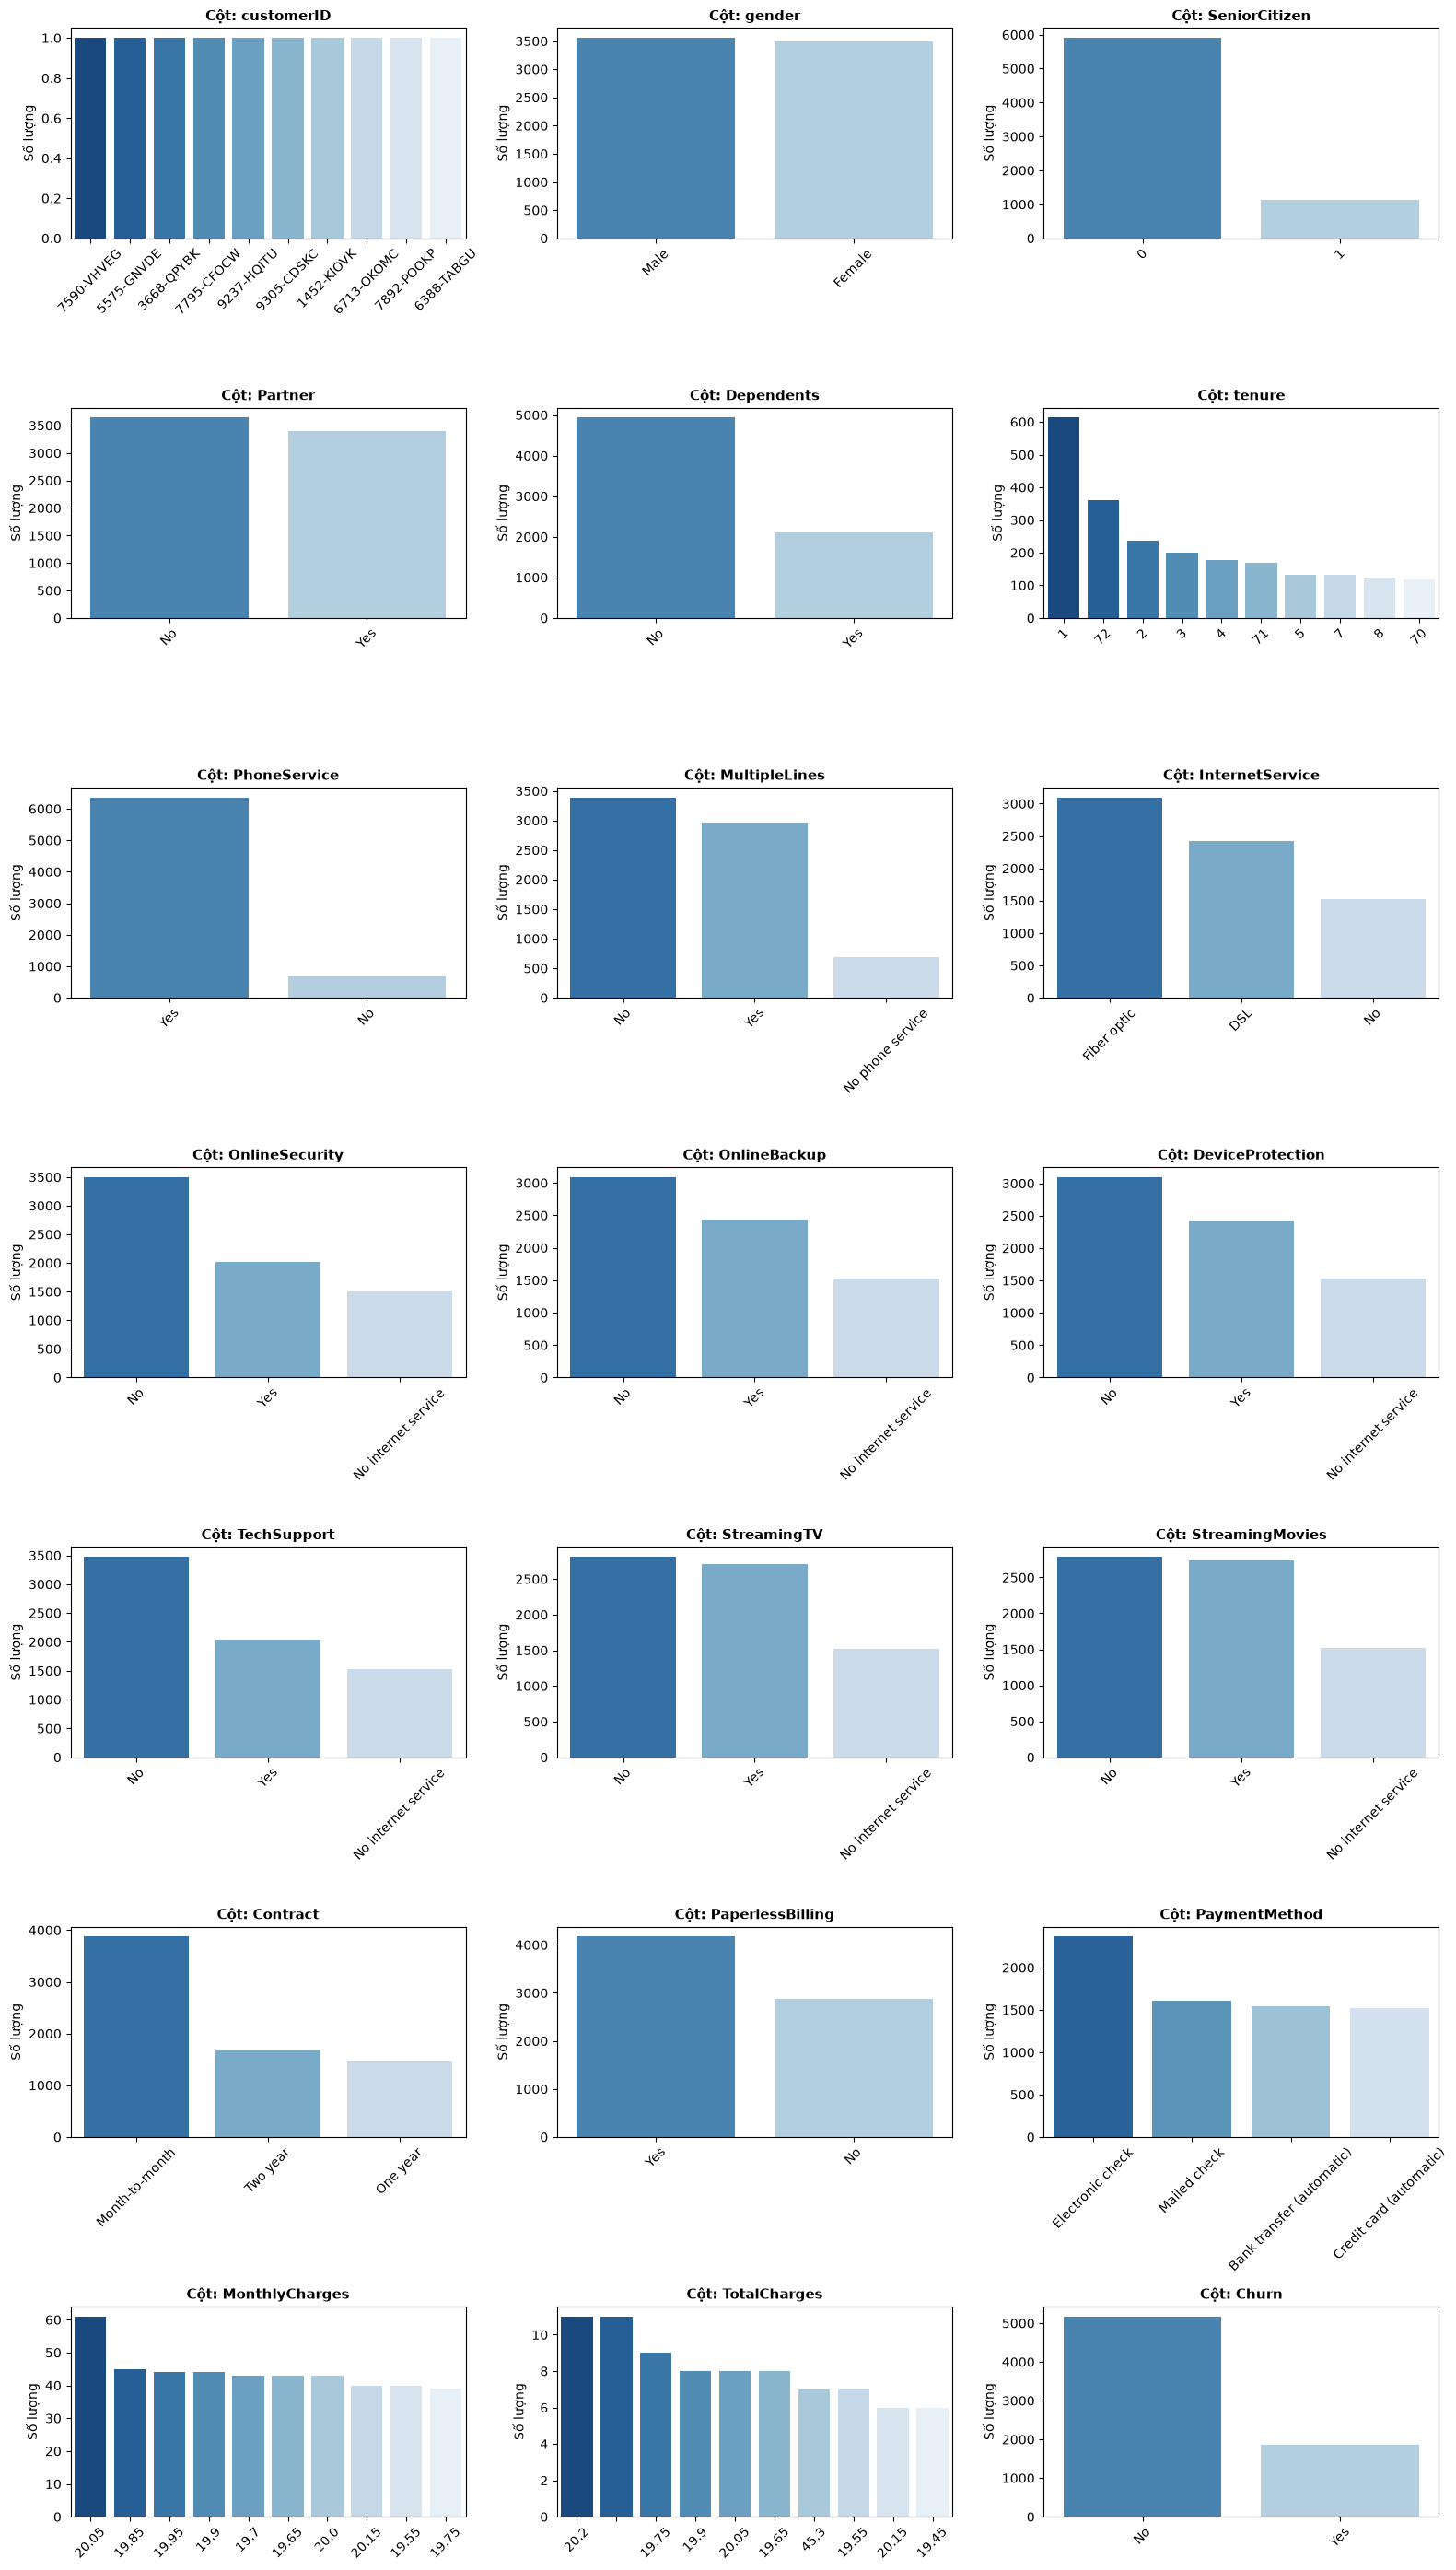

In [71]:
# 1. Cấu hình lưới subplot (ví dụ: tối đa 3 biểu đồ trên 1 hàng)
n_cols_df = len(df.columns)
n_grid_cols = 3  
n_grid_rows = math.ceil(n_cols_df / n_grid_cols)

# Tạo khung hình lưới
fig, axes = plt.subplots(n_grid_rows, n_grid_cols, figsize=(16, 4 * n_grid_rows))
# Đảm bảo axes luôn là mảng 1 chiều để dễ duyệt qua (tránh lỗi nếu DataFrame chỉ có 1-2 cột)
axes = axes.flatten() if n_cols_df > 1 else [axes]

# 2. Vòng lặp vẽ biểu đồ cho từng cột tương tự logic của bạn
for i, col in enumerate(df.columns):
    ax = axes[i]
    
    # Lấy value_counts (tính cả NaN), giới hạn top 10 giá trị phổ biến nhất để biểu đồ không bị tràn
    vc = df[col].value_counts(dropna=False).head(10)
    
    # Chuyển index sang chuỗi (để hiển thị nhãn 'nan' hoặc các giá trị đặc biệt rõ ràng)
    x_labels = [str(val) for val in vc.index]
    
    # Vẽ biểu đồ cột
    sns.barplot(x=x_labels, y=vc.values, ax=ax, palette='Blues_r')
    
    ax.set_title(f'Cột: {col}', fontsize=11, fontweight='bold')
    ax.tick_params(axis='x', rotation=45)
    ax.set_ylabel('Số lượng')
    ax.set_xlabel('')

# 3. Xóa các ô subplot dư thừa (nếu tổng số cột không chia hết cho n_grid_cols)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**Kết quả:** Chỉ `TotalCharges` thiếu 11 giá trị. Các dòng này đều có `tenure = 0` (khách mới) → sau này điền bằng 0.

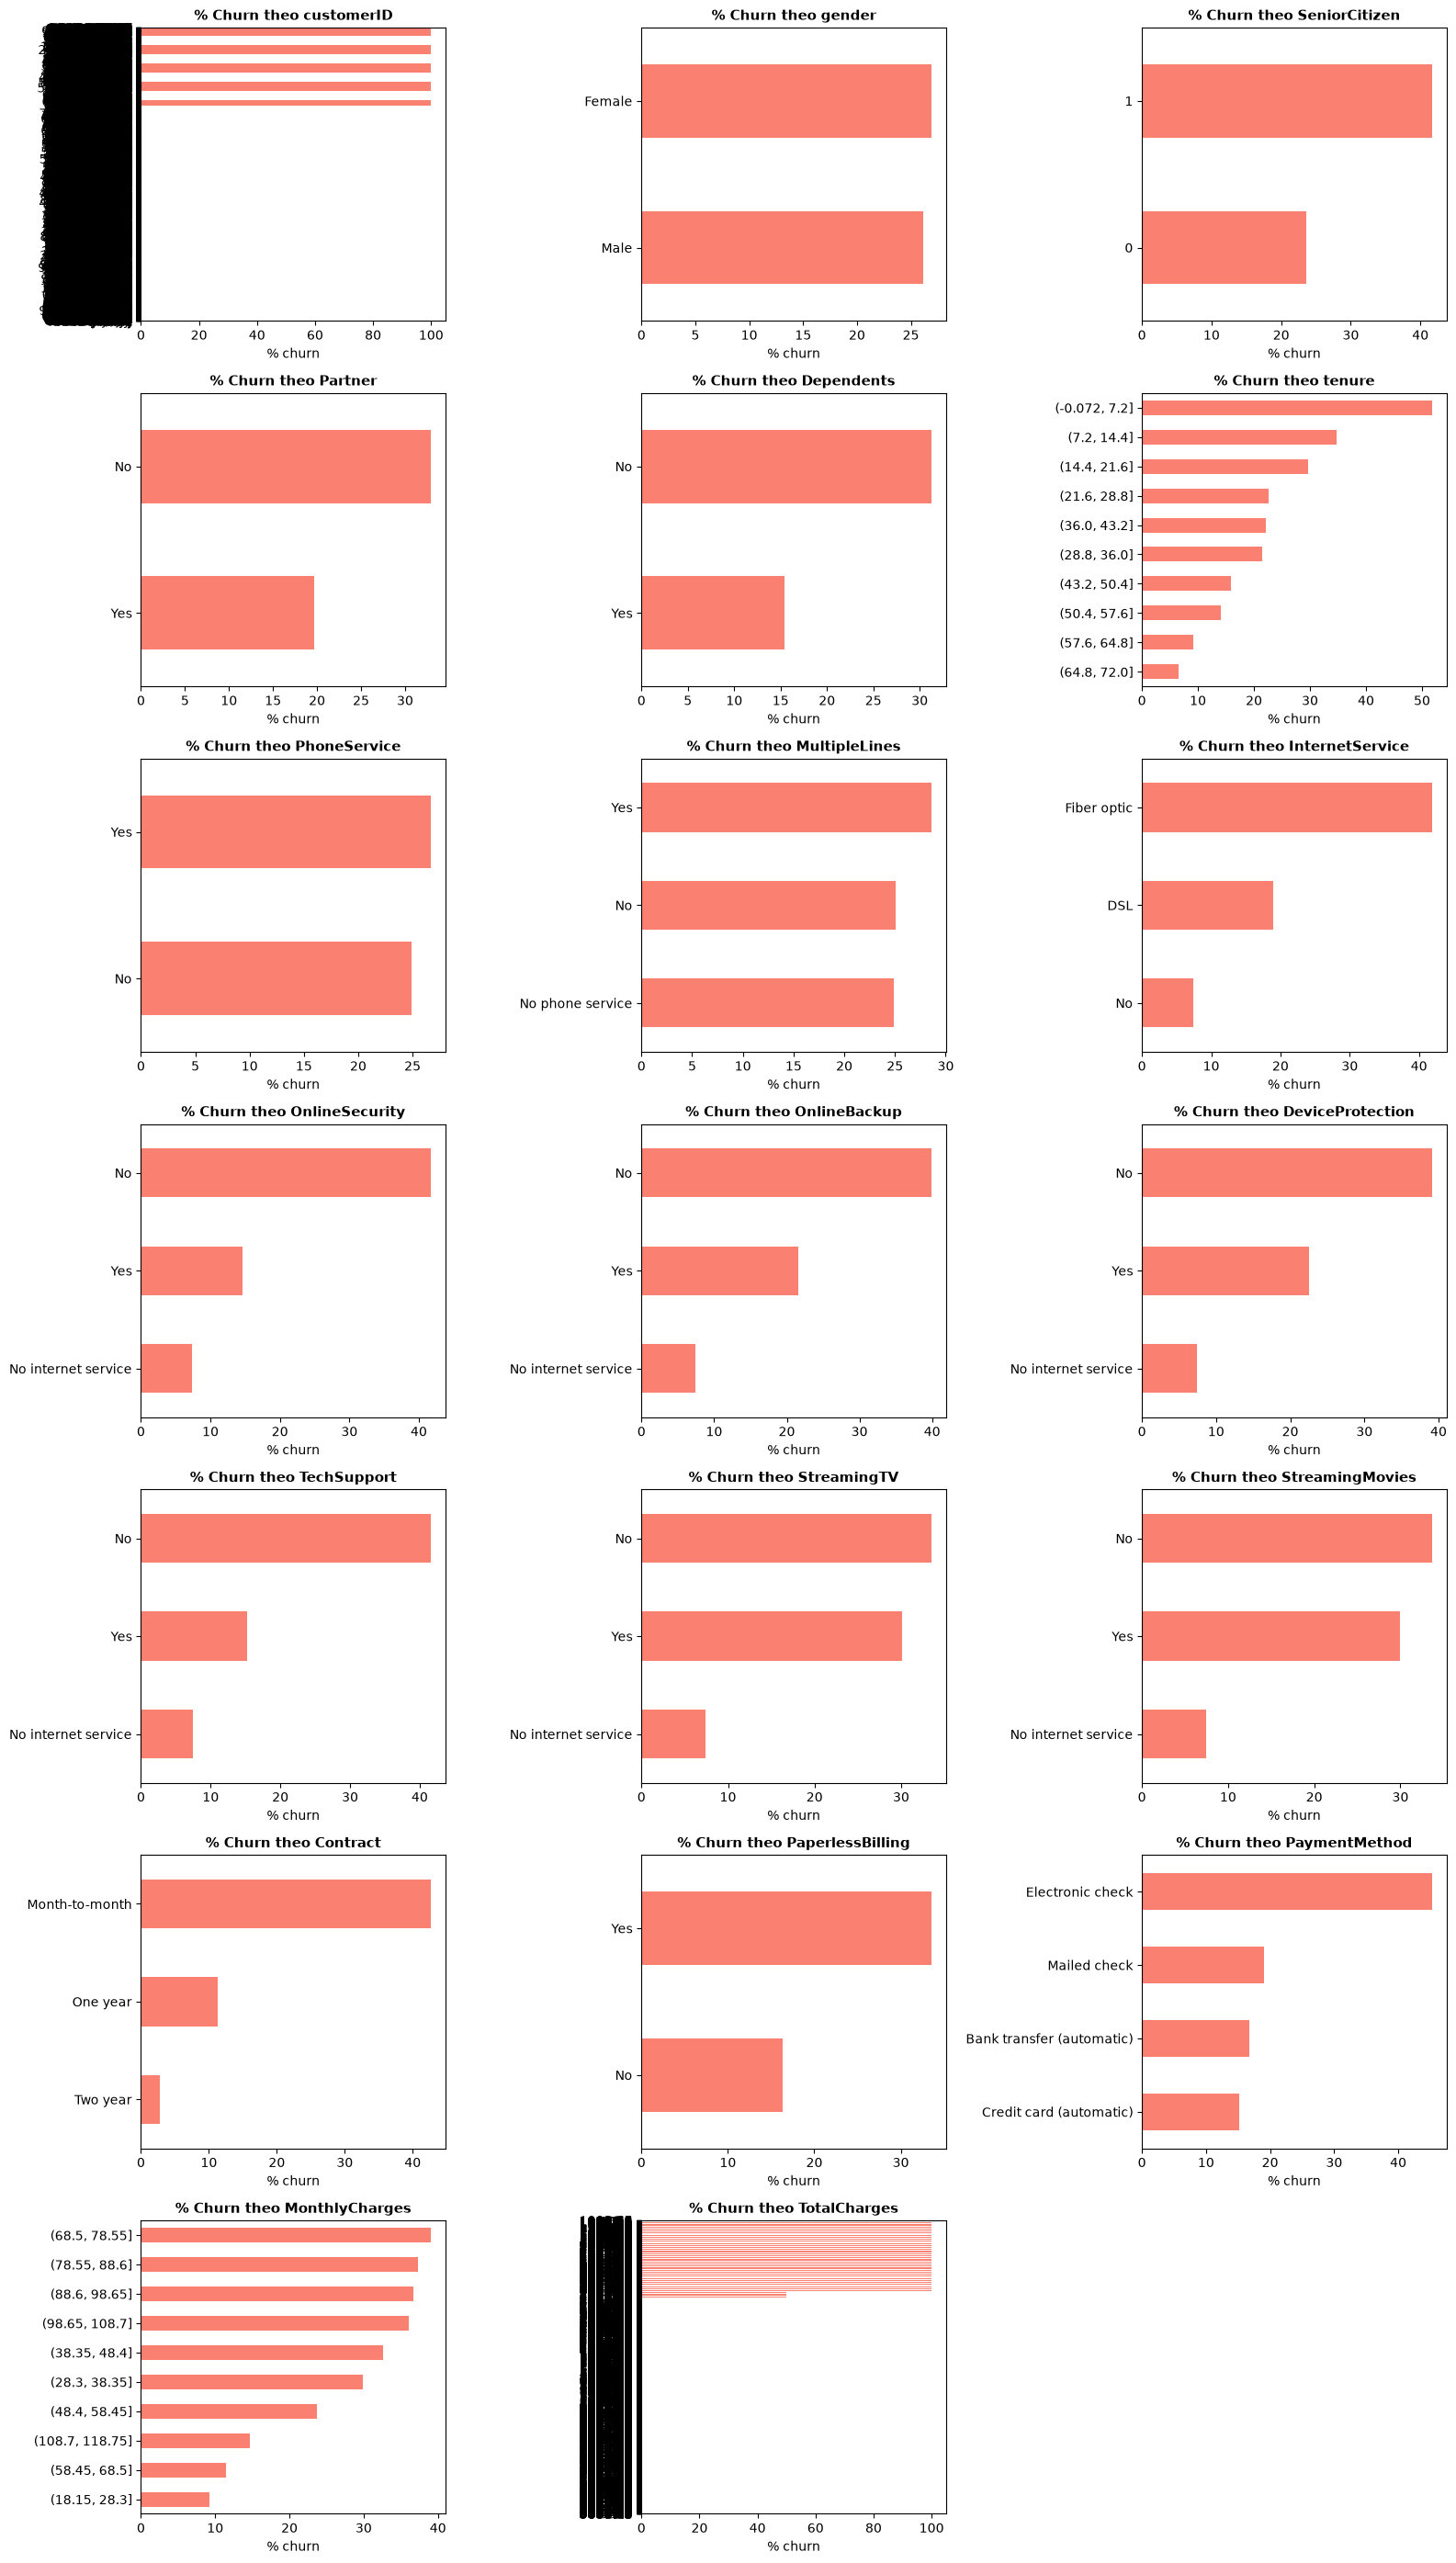

In [72]:
# Lọc bỏ cột 'Churn'
cols = [col for col in df.columns if col != 'Churn']

n_cols = len(cols)
n_grid_cols = 3
n_grid_rows = math.ceil(n_cols / n_grid_cols)

fig, axes = plt.subplots(n_grid_rows, n_grid_cols, figsize=(16, 4 * n_grid_rows))
axes = axes.flatten() if n_cols > 1 else [axes]

for i, col in enumerate(cols):
  ax = axes[i]

  # Kiểm tra nếu cột là kiểu số liên tục (có nhiều giá trị duy nhất như tenure, charges)
  if pd.api.types.is_numeric_dtype(df[col]) and df[col].nunique() > 10:
    # Chia thành 10 khoảng (bins) để dễ nhìn xu hướng churn theo mức độ
    temp_col = pd.cut(df[col], bins=10)
    pct = df.groupby(temp_col, observed=False)['Churn'].apply(
        lambda x: (x == 'Yes').mean() * 100
    )
    # Chuyển index thành chuỗi ngắn gọn cho trục Y
    pct.index = [str(interval) for interval in pct.index]
  else:
    # Cột phân loại bình thường
    pct = df.groupby(col)['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)

  # Vẽ biểu đồ cột ngang
  pct.sort_values().plot(kind='barh', ax=ax, color='salmon')

  ax.set_title(f'% Churn theo {col}', fontsize=11, fontweight='bold')
  ax.set_xlabel('% churn')
  ax.set_ylabel('')

# Xóa các ô subplot dư thừa
for j in range(i + 1, len(axes)):
  fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

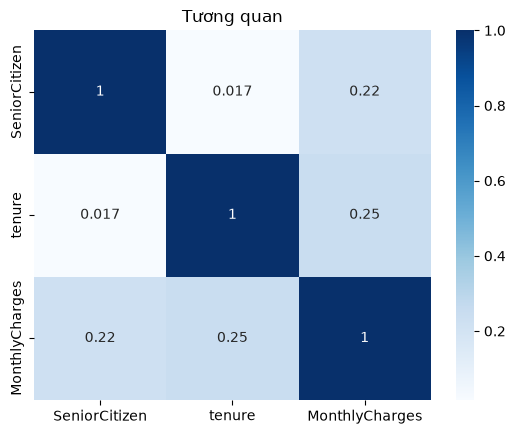

In [73]:
# Tương quan các cột số
sns.heatmap(df[num_cols].corr(), annot=True, cmap='Blues')
plt.title('Tương quan')
plt.show()